**Why Visualization is Essential in the ML Workflow**

- It is not about creating pretty charts

- It is a computational & intuitive tool for understanding data structures, uncovering hidden patterns, and interpreting model behavior

**The ML Visualization Pipeline**

*Phase 1*

- Exploratory Data Analysis & Preprocessing

*Phase 2*

- Feature Engineering

*Phase 3*

- Confusion Matrices

- Bias vs. Variance

- Decision Boundaries

**The Python Visualization Toolkit**

- Matplotlib: Low level visualization library

- Seaborn: High-level visualization library

- Pandas & Numpy

In [1]:
# Import Basic Toolkit/Seeting up the environment
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Our Data of Interest
pd.set_option('display.max_columns', None)
us_edu_data = pd.read_csv('/content/drive/MyDrive/Data/us_education_system_dataset.csv')
us_edu_data.head()

,institution_id,institution_name,state_code,state_name,county,nces_locale,level,control,title_i_status,total_enrollment,number_of_teachers,student_teacher_ratio,percent_free_reduced_lunch,racial_white_pct,racial_black_pct,racial_hispanic_pct,racial_asian_pct,racial_native_pct,racial_two_or_more_pct,special_education_pct,english_learner_pct,per_pupil_expenditure_usd,federal_funding_pct,state_funding_pct,local_funding_pct,math_proficiency_pct,reading_proficiency_pct,graduation_rate_pct,chronic_absenteeism_pct,avg_sat_score,avg_act_score,ap_ib_participation_pct,postsecondary_enrollment_pct,stem_certified_flag,broadband_access_pct
0,US-EDU-10001,Jefferson Elementary School,MA,Massachusetts,Central County,Suburban - Midsize,Elementary School,Public,Title I Schoolwide,447,30,14.8,48.9,70.9,2.4,15.4,8.1,0.1,3.1,14.4,12.9,12840,15.0,54.8,30.2,58.3,58.1,80.9,18.0,NaN,NaN,NaN,NaN,No,91.6
1,US-EDU-10002,Lakeshore Middle School,FL,Florida,Miami-Dade County,Suburban - Midsize,Middle School,Private Religious,Not Applicable,293,29,10.0,1.2,34.7,8.6,36.1,13.3,1.3,6.0,13.7,19.3,17009,0.0,2.0,98.0,84.8,98.0,93.5,17.8,NaN,NaN,NaN,NaN,No,94.4
2,US-EDU-10003,Meadowbrook Elementary Academy,TX,Texas,Bexar County,City - Large,Elementary School,Private For-Profit,Not Applicable,315,17,18.2,36.0,26.2,29.2,22.9,12.3,1.9,7.5,15.7,11.3,15374,10.7,55.5,33.8,54.6,66.2,80.2,19.5,NaN,NaN,NaN,NaN,No,94.0
3,US-EDU-10004,Roosevelt Primary School,FL,Florida,Palm Beach County,Suburban - Large,Elementary School,Public,Not Title I Eligible,389,34,11.3,15.1,49.2,16.7,4.3,26.4,0.1,3.3,13.8,9.8,17065,6.8,38.3,54.9,66.1,70.5,82.1,20.5,NaN,NaN,NaN,NaN,No,96.4
4,US-EDU-10005,Highland Park Primary School,MI,Michigan,Macomb County,Suburban - Large,Elementary School,Public,Title I Targeted,397,29,13.9,45.6,78.1,3.2,8.0,3.9,2.1,4.7,19.8,5.3,16823,15.0,42.3,42.7,54.6,46.7,90.2,19.9,NaN,NaN,NaN,NaN,No,86.3


In [4]:
# Look at the column names
us_edu_data.columns

Index(['institution_id', 'institution_name', 'state_code', 'state_name',
       'county', 'nces_locale', 'level', 'control', 'title_i_status',
       'total_enrollment', 'number_of_teachers', 'student_teacher_ratio',
       'percent_free_reduced_lunch', 'racial_white_pct', 'racial_black_pct',
       'racial_hispanic_pct', 'racial_asian_pct', 'racial_native_pct',
       'racial_two_or_more_pct', 'special_education_pct',
       'english_learner_pct', 'per_pupil_expenditure_usd',
       'federal_funding_pct', 'state_funding_pct', 'local_funding_pct',
       'math_proficiency_pct', 'reading_proficiency_pct',
       'graduation_rate_pct', 'chronic_absenteeism_pct', 'avg_sat_score',
       'avg_act_score', 'ap_ib_participation_pct',
       'postsecondary_enrollment_pct', 'stem_certified_flag',
       'broadband_access_pct'],
      dtype='object')

In [ ]:
# Key Metric Across Academic Institutions
# Institutional Context: level, control, title status, location
# Resources & Expenditure: total enrollment, student-teacher ratio, pupil per expenditure, broadband access
# Demographics & Needs: percent_free_reduced_lunch, special_education_pct, english_learner_pct
# Academic Outcomes: math_proficiency_pct, graduation_rate_pct, avg_sat_score, avg_act_score, postsecondary_enrollment_pct

In [7]:
# Key Metrics Dataframe
us_edu_keymetrics_data = us_edu_data[['institution_name', 'title_i_status','level', 'control',
                          'per_pupil_expenditure_usd', 'percent_free_reduced_lunch',
                          'math_proficiency_pct', 'graduation_rate_pct' ]]

In [8]:
us_edu_keymetrics_data.head()

,institution_name,title_i_status,level,control,per_pupil_expenditure_usd,percent_free_reduced_lunch,math_proficiency_pct,graduation_rate_pct
0,Jefferson Elementary School,Title I Schoolwide,Elementary School,Public,12840,48.9,58.3,80.9
1,Lakeshore Middle School,Not Applicable,Middle School,Private Religious,17009,1.2,84.8,93.5
2,Meadowbrook Elementary Academy,Not Applicable,Elementary School,Private For-Profit,15374,36.0,54.6,80.2
3,Roosevelt Primary School,Not Title I Eligible,Elementary School,Public,17065,15.1,66.1,82.1
4,Highland Park Primary School,Title I Targeted,Elementary School,Public,16823,45.6,54.6,90.2


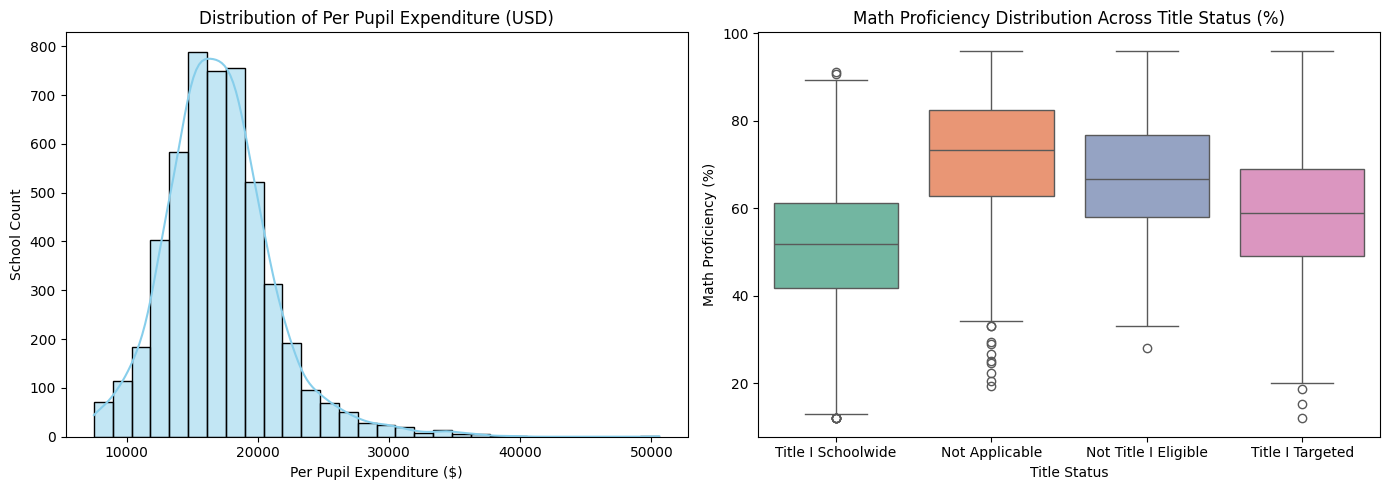

In [12]:
# Univariate Analysis - Inspect Distributions & Skewness
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot - Histogram: Distribution of Expenditure(per_pupil_expenditure_usd)
sns.histplot(us_edu_keymetrics_data['per_pupil_expenditure_usd'], kde=True, ax=axes[0], color='skyblue', bins=30)
axes[0].set_title('Distribution of Per Pupil Expenditure (USD)')
axes[0].set_xlabel('Per Pupil Expenditure ($)')
axes[0].set_ylabel('School Count')

# Plot 2 - Math Proficiency Distribution Across Title Status
sns.boxplot(data=us_edu_keymetrics_data, x='title_i_status', y='math_proficiency_pct', hue='title_i_status', legend=False, ax=axes[1], palette='Set2')
axes[1].set_title('Math Proficiency Distribution Across Title Status (%)')
axes[1].set_xlabel('Title Status')
axes[1].set_ylabel('Math Proficiency (%)')

plt.tight_layout()
plt.show()

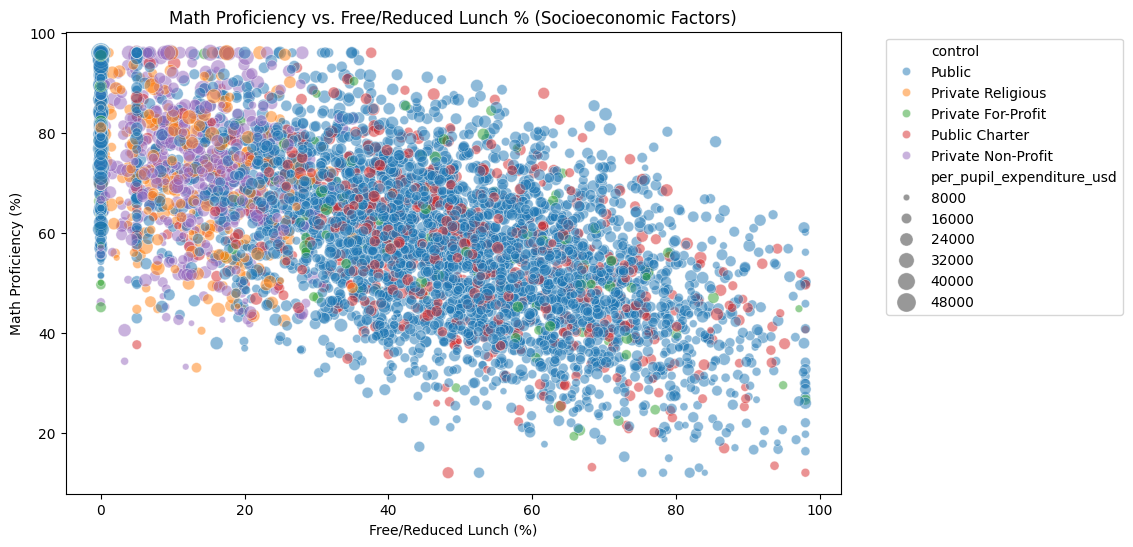

In [25]:
# Bivariate &amp; Multivariate Analysis — Uncovering Feature Interactions
# Faceted Scatter Plot with color & Size Mapping
plt.figure(figsize=(10, 6))

sns.scatterplot(data=us_edu_keymetrics_data, x='percent_free_reduced_lunch',
                y='math_proficiency_pct', hue='control',
                size='per_pupil_expenditure_usd',
                sizes=(20, 200),
                alpha=0.5)

plt.title('Math Proficiency vs. Free/Reduced Lunch % (Socioeconomic Factors)')
plt.xlabel('Free/Reduced Lunch (%)')
plt.ylabel('Math Proficiency (%)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout
plt.show()